## Import libraries

In [78]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


 ## Set dataset path

In [79]:
DATA_PATH = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc.zip"


## Check the dataset directory

In [80]:
import os

DATA_PATH = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc.zip"

print("Dataset exists:", os.path.exists(DATA_PATH))
print("Is file:", os.path.isfile(DATA_PATH))

Dataset exists: True
Is file: True


In [81]:
import os
import zipfile

ZIP_PATH = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc.zip"
EXTRACT_PATH = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc"

# Check ZIP exists
print("ZIP exists:", os.path.exists(ZIP_PATH))

# Extract
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Extracted successfully!")
print("Files/Folders:")
print(os.listdir(EXTRACT_PATH))

ZIP exists: True
Extracted successfully!
Files/Folders:
['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


In [82]:
DATA_PATH = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc"

print(os.listdir(DATA_PATH))

['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


In [83]:
import os

for root, dirs, files in os.walk(DATA_PATH):
    for file in files:
        print(os.path.join(root, file))

C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta.csv
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Test.csv
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Train.csv
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\.~lock.ClassesInformation.ods#
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\.~lock.ClassesInformationStrong.ods#
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\0.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\1.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\10.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\11.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\12.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\13.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\14.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\15.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\16.png
C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Meta\17.png
C:\Users\venka\Downloads\P

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [84]:
print("Dataset exists:", os.path.exists(DATA_PATH))

print("\nFolders:")
print(os.listdir(DATA_PATH))

Dataset exists: True

Folders:
['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


## Identify classes

In [85]:
classes = sorted([
    folder for folder in os.listdir(DATA_PATH)
    if os.path.isdir(os.path.join(DATA_PATH, folder))
])

print("Number of classes:", len(classes))
print("\nClasses:")
for i, cls in enumerate(classes):
    print(i, ":", cls)

Number of classes: 3

Classes:
0 : Meta
1 : Test
2 : Train


## Count images in each class

In [86]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

class_counts = {}

for cls in classes:
    folder = os.path.join(DATA_PATH, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ])

    class_counts[cls] = count

class_counts

{'Meta': 43, 'Test': 12630, 'Train': 0}

## Create class-count DataFrame

In [87]:
class_df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Image_Count"]
)

class_df

,Class,Image_Count
0,Meta,43
1,Test,12630
2,Train,0


## Plot number of images per class

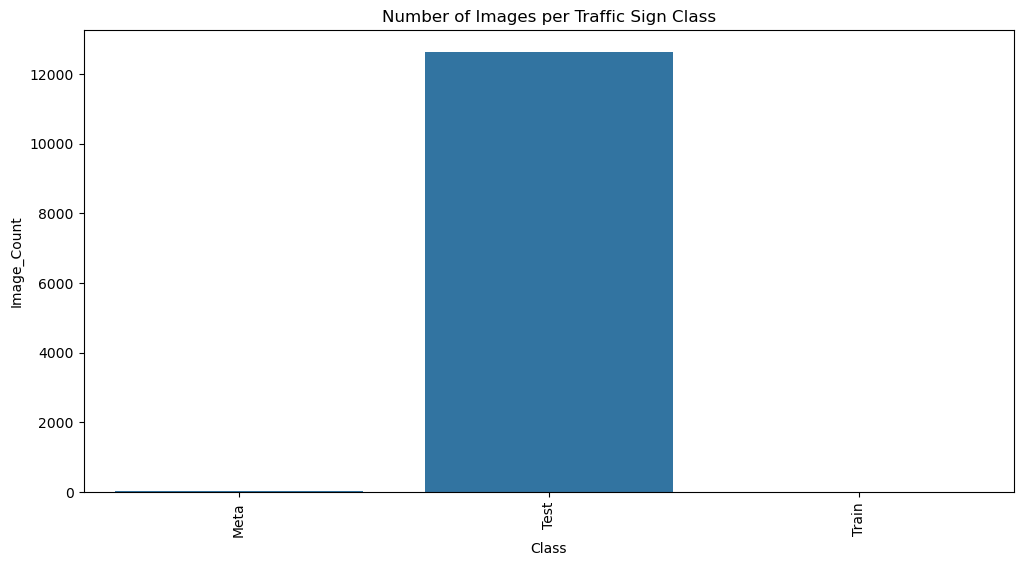

In [88]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_df,
    x="Class",
    y="Image_Count"
)

plt.title("Number of Images per Traffic Sign Class")
plt.xticks(rotation=90)
plt.show()

## Total number of images

In [89]:
total_images = class_df["Image_Count"].sum()

print("Total images:", total_images)

Total images: 12673


## Display sample images

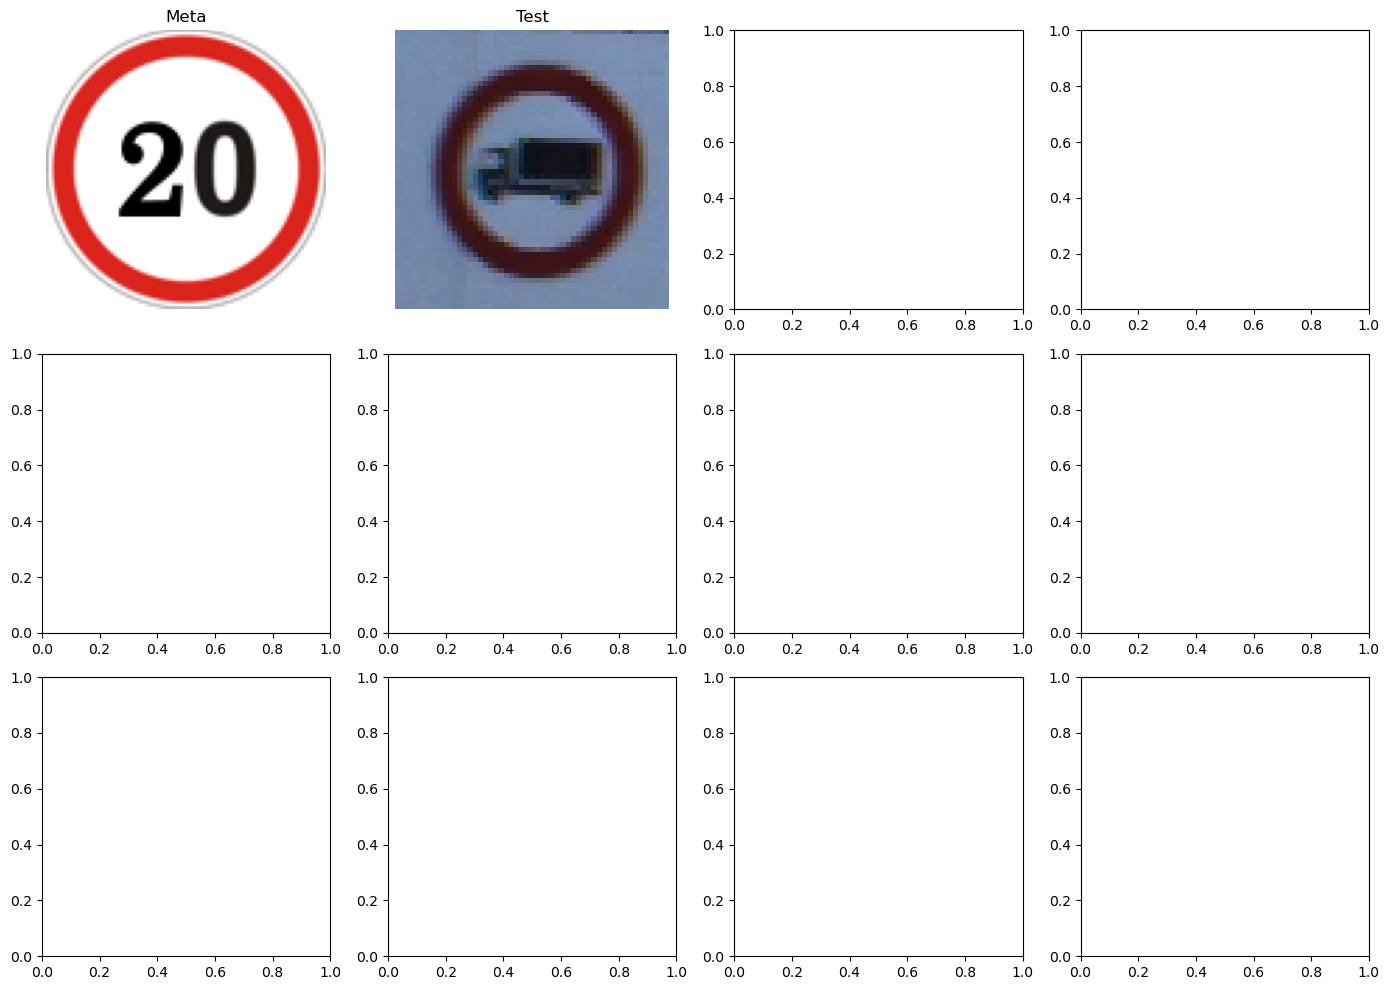

In [90]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(14, 10)
)

for ax, cls in zip(axes.flatten(), classes[:12]):

    folder = os.path.join(DATA_PATH, cls)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ]

    if images:
        image_path = os.path.join(folder, images[0])

        img = Image.open(image_path)

        ax.imshow(img)
        ax.set_title(cls)
        ax.axis("off")

plt.tight_layout()
plt.show()

## Inspect image dimensions

In [91]:
image_info = []

for cls in classes:

    folder = os.path.join(DATA_PATH, cls)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ]

    for img_file in images[:20]:

        path = os.path.join(folder, img_file)

        try:
            img = Image.open(path)

            image_info.append({
                "Class": cls,
                "Width": img.width,
                "Height": img.height,
                "Mode": img.mode
            })

        except Exception as e:
            print("Error:", path, e)

image_info_df = pd.DataFrame(image_info)

image_info_df.head()

,Class,Width,Height,Mode
0,Meta,100,100,RGBA
1,Meta,100,100,RGBA
2,Meta,100,100,RGBA
3,Meta,100,88,RGBA
4,Meta,100,100,RGBA


## Image dimension statistics

In [92]:
image_info_df.describe(include="all")

,Class,Width,Height,Mode
count,40,40.00000,40.000000,40
unique,2,NaN,NaN,2
top,Meta,NaN,NaN,RGBA
freq,20,NaN,NaN,20
mean,NaN,74.82500,71.650000,NaN
std,NaN,31.83925,27.983099,NaN
min,NaN,27.00000,27.000000,NaN
25%,NaN,42.75000,43.250000,NaN
50%,NaN,100.00000,88.000000,NaN
75%,NaN,100.00000,91.750000,NaN


## Width distribution

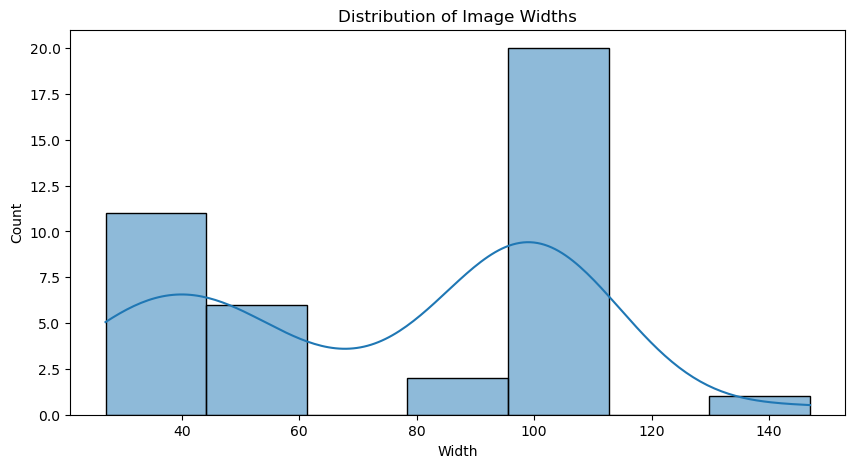

In [93]:
plt.figure(figsize=(10, 5))

sns.histplot(
    image_info_df["Width"],
    kde=True
)

plt.title("Distribution of Image Widths")
plt.show()

## Height distribution

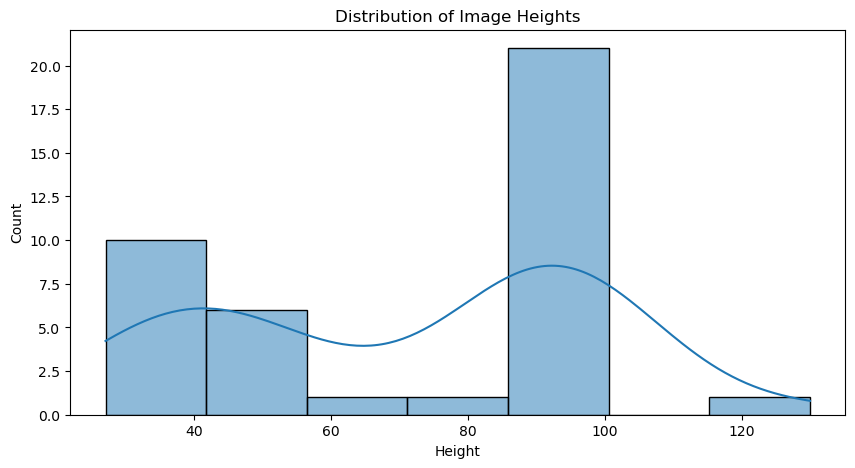

In [94]:
plt.figure(figsize=(10, 5))

sns.histplot(
    image_info_df["Height"],
    kde=True
)

plt.title("Distribution of Image Heights")
plt.show()

## Check image modes

In [95]:
image_info_df["Mode"].value_counts()

Mode
RGBA    20
RGB     20
Name: count, dtype: int64

## Check corrupted images

In [96]:
corrupted_images = []

for cls in classes:

    folder = os.path.join(DATA_PATH, cls)

    for file in os.listdir(folder):

        if not file.lower().endswith(image_extensions):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception:
            corrupted_images.append(path)

print("Corrupted images:", len(corrupted_images))

for path in corrupted_images[:10]:
    print(path)

Corrupted images: 0


## Set image parameters

In [97]:
IMG_SIZE = 64
BATCH_SIZE = 32
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 64
Batch size: 32


## Create training data generator

In [98]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,

    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,

    horizontal_flip=False
)

## Create training generator

In [99]:
train_generator = train_datagen.flow_from_directory(
    DATA_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
)
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED
)

Found 41507 images belonging to 3 classes.


## Create validation generator

In [100]:
validation_generator = train_datagen.flow_from_directory(
    DATA_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=SEED
)

Found 10375 images belonging to 3 classes.


## Display class indices

In [101]:
class_indices = train_generator.class_indices

class_indices

{'Meta': 0, 'Test': 1, 'Train': 2}

## Reverse class mapping

In [102]:
index_to_class = {
    value: key
    for key, value in class_indices.items()
}

index_to_class

{0: 'Meta', 1: 'Test', 2: 'Train'}

## Inspect one batch

In [103]:
images, labels = next(train_generator)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32, 3)


## Display augmented images

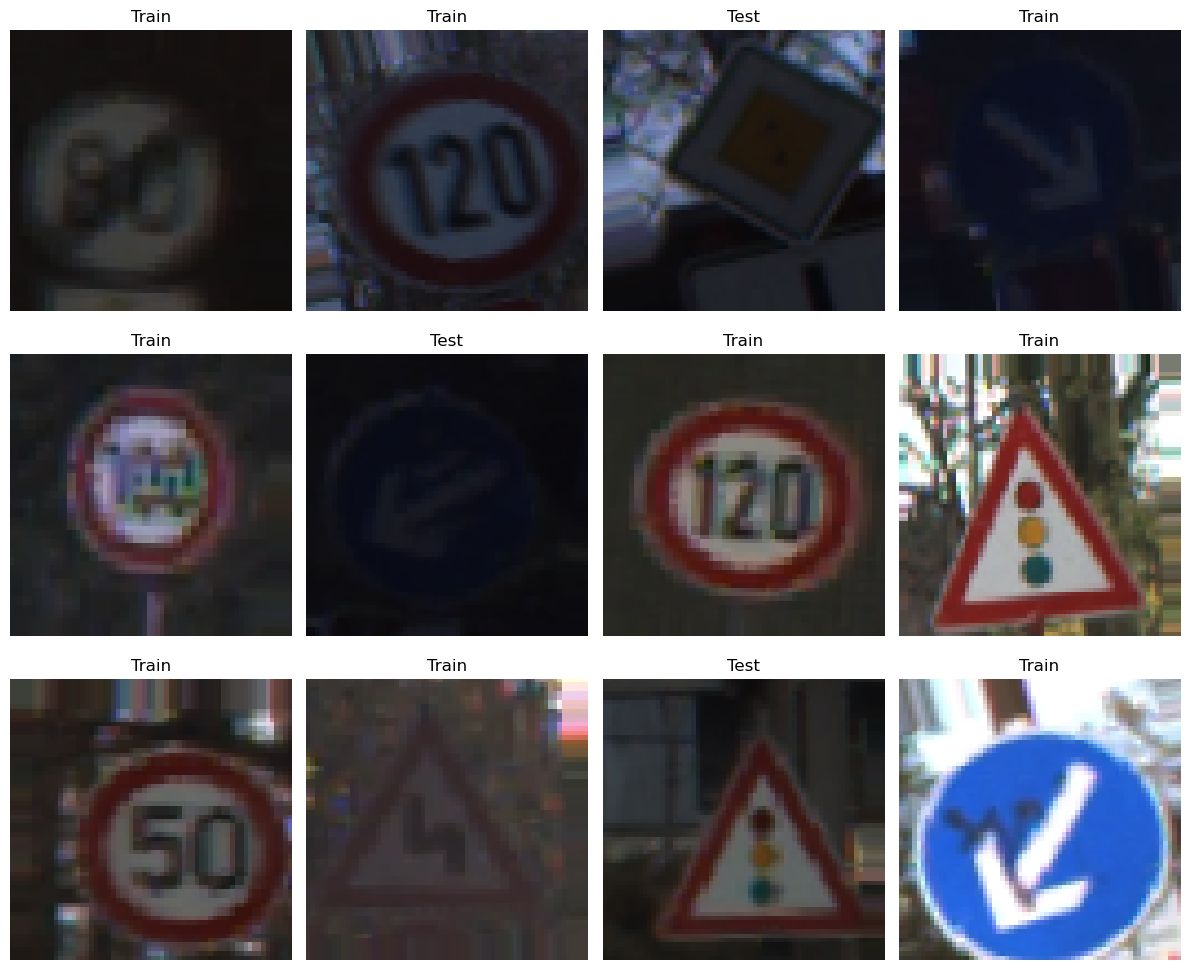

In [104]:
plt.figure(figsize=(12, 10))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i])

    class_index = np.argmax(labels[i])

    plt.title(
        index_to_class[class_index]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## Number of classes

In [105]:
NUM_CLASSES = len(train_generator.class_indices)

print("Number of classes:", NUM_CLASSES)

Number of classes: 3


## Build CNN architecture

In [106]:
model = models.Sequential([

    layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 683,587 (2.61 MB)

 Trainable params: 683,587 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## Compile CNN

In [107]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


## Early stopping

In [108]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## Model checkpoint

In [109]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_traffic_sign_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

## Train CNN

In [110]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 1758s 1s/step - accuracy: 0.7553 - loss: 0.5698 - val_accuracy: 0.7300 - val_loss: 0.5838
Epoch 2/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 792s 609ms/step - accuracy: 0.7567 - loss: 0.5587 - val_accuracy: 0.7549 - val_loss: 0.5577
Epoch 3/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 417s 322ms/step - accuracy: 0.7569 - loss: 0.5591 - val_accuracy: 0.7565 - val_loss: 0.5559
Epoch 4/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 4328s 3s/step - accuracy: 0.7565 - loss: 0.5572 - val_accuracy: 0.7564 - val_loss: 0.5554
Epoch 5/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 42260s 33s/step - accuracy: 0.7566 - loss: 0.5560 - val_accuracy: 0.7565 - val_loss: 0.5548
Epoch 6/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 483s 372ms/step - accuracy: 0.7566 - loss: 0.5561 - val_accuracy: 0.7566 - val_loss: 0.5560
Epoch 7/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 418s 305ms/step - accuracy: 0.7566 - loss: 0.5555 - val_accuracy: 0.7562 - val_loss: 0.5553
Epoch 8/30
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 457s 352ms/step - accura

## Training history

In [111]:
   history_df = pd.DataFrame(
    history.history
)  

history_df.head()


,accuracy,loss,val_accuracy,val_loss
0,0.755270,0.569848,0.730024,0.583807
1,0.756668,0.558744,0.754892,0.557718
2,0.756908,0.559100,0.756530,0.555855
3,0.756547,0.557155,0.756434,0.555420
4,0.756595,0.555968,0.756530,0.554846


## Training vs validation accuracy

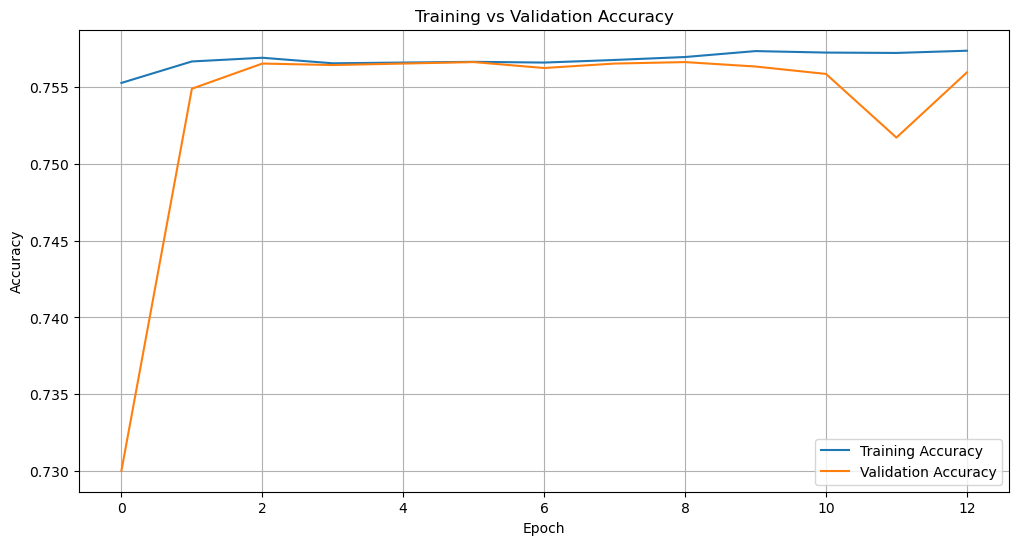

In [112]:
plt.figure(figsize=(12, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

## Training vs validation loss

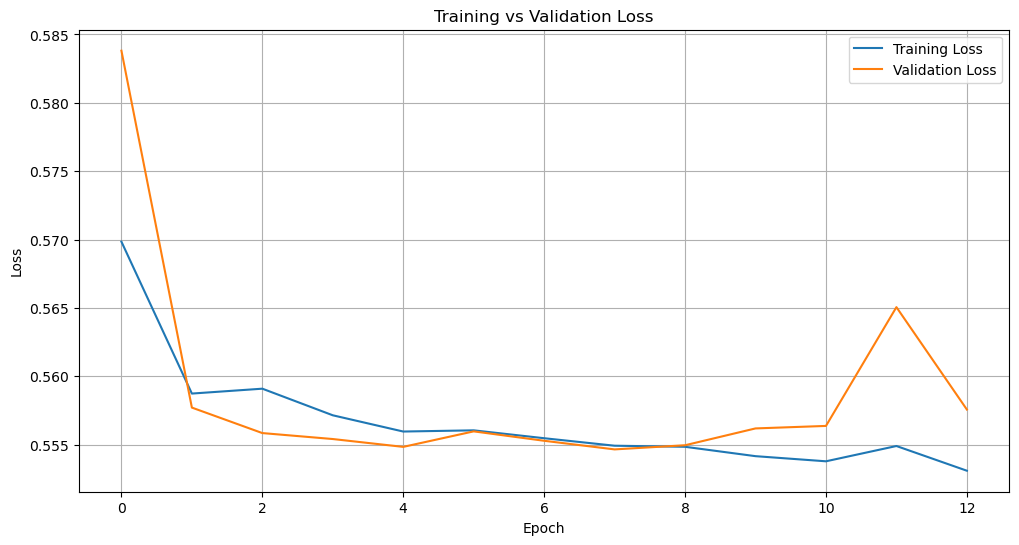

In [113]:
plt.figure(figsize=(12, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

## Evaluate validation dataset

In [114]:
validation_loss, validation_accuracy = model.evaluate(
    validation_generator
)

print(
    "Validation Loss:",
    validation_loss
)

print(
    "Validation Accuracy:",
    validation_accuracy
)

325/325 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - accuracy: 0.7565 - loss: 0.5546
Validation Loss: 0.5546364188194275
Validation Accuracy: 0.7565301060676575


## Generate predictions

In [115]:
 validation_generator.reset()

pred_probabilities = model.predict(
    validation_generator
)

pred_classes = np.argmax(
    pred_probabilities,
    axis=1
)

true_classes = validation_generator.classes

325/325 ━━━━━━━━━━━━━━━━━━━━ 37s 112ms/step


## Classification accuracy

In [ ]:
accuracy = accuracy_score(
    true_classes,
    pred_classes
)

print(
    "Validation Accuracy:",
    accuracy
)

## Classification report

In [117]:
target_names = [
    index_to_class[i]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    true_classes,
    pred_classes,
    target_names=target_names
)

print(report)

              precision    recall  f1-score   support

        Meta       1.00      1.00      1.00         8
        Test       1.00      0.00      0.00      2526
       Train       0.76      1.00      0.86      7841

    accuracy                           0.76     10375
   macro avg       0.92      0.67      0.62     10375
weighted avg       0.82      0.76      0.65     10375



## Confusion matrix

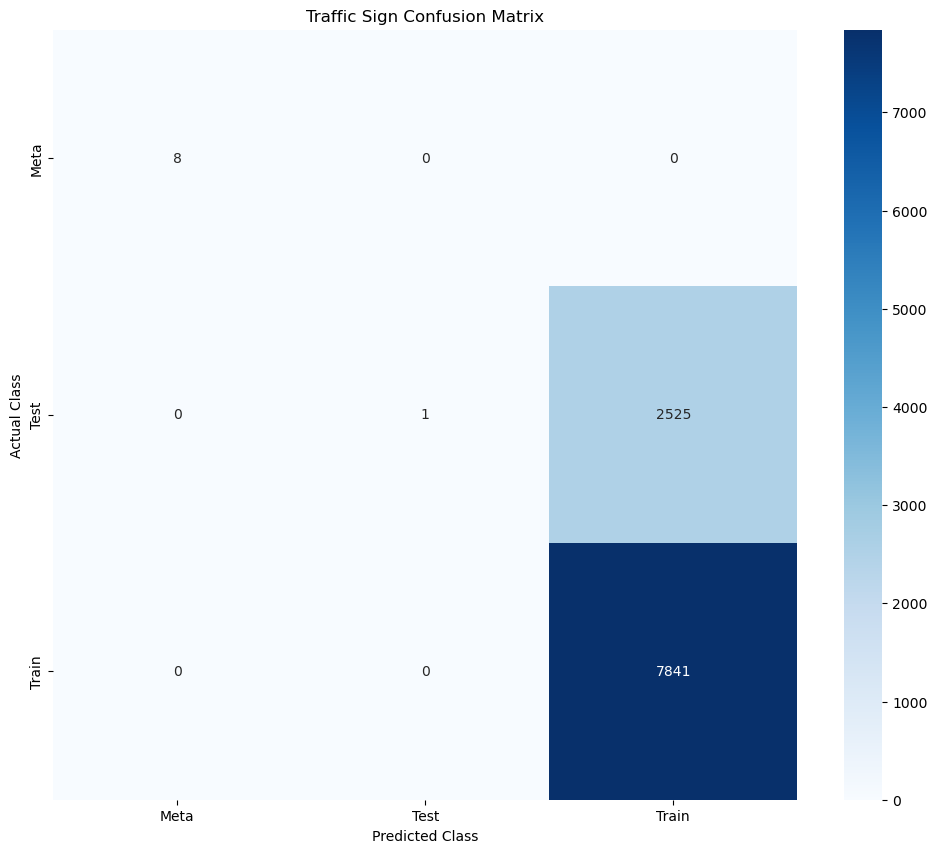

In [118]:
cm = confusion_matrix(
    true_classes,
    pred_classes
)

plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title(
    "Traffic Sign Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()

## Class-wise accuracy

In [119]:
class_accuracy = (
    cm.diagonal() /
    cm.sum(axis=1)
)

class_accuracy_df = pd.DataFrame({
    "Class": target_names,
    "Accuracy": class_accuracy
})

class_accuracy_df

,Class,Accuracy
0,Meta,1.000000
1,Test,0.000396
2,Train,1.000000


## Plot class-wise accuracy

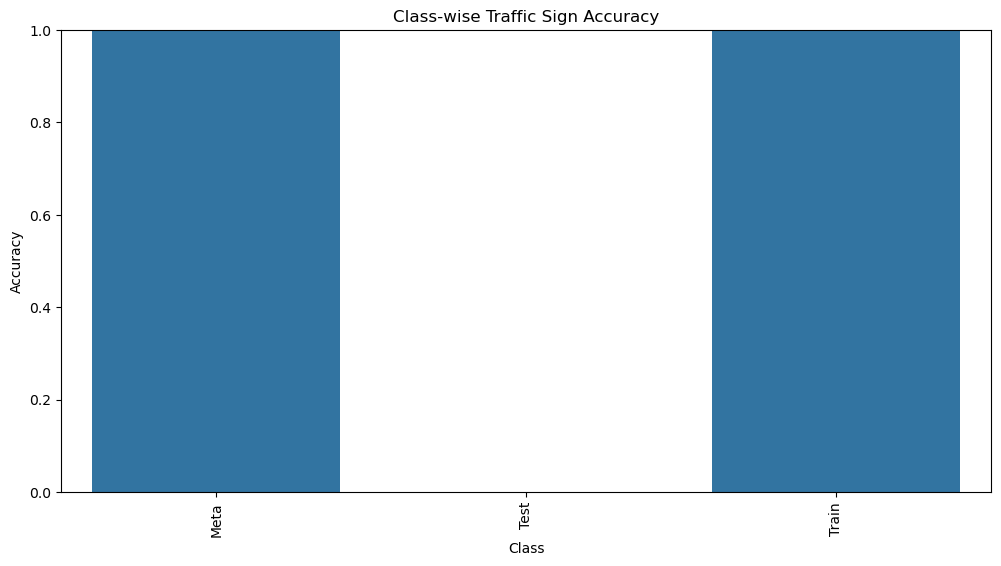

In [120]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_accuracy_df,
    x="Class",
    y="Accuracy"
)

plt.title(
    "Class-wise Traffic Sign Accuracy"
)

plt.xticks(rotation=90)

plt.ylim(0, 1)

plt.show()

## Find misclassified images

In [121]:
validation_generator.reset()

all_images = []
all_labels = []

for batch_images, batch_labels in validation_generator:

    all_images.extend(batch_images)
    all_labels.extend(
        np.argmax(batch_labels, axis=1)
    )

    if len(all_images) >= len(true_classes):
        break

all_images = np.array(
    all_images[:len(true_classes)]
)

all_labels = np.array(
    all_labels[:len(true_classes)]
)

misclassified = (
    all_labels != pred_classes
)

print(
    "Misclassified images:",
    misclassified.sum()
)

Misclassified images: 2525


## Display misclassified examples

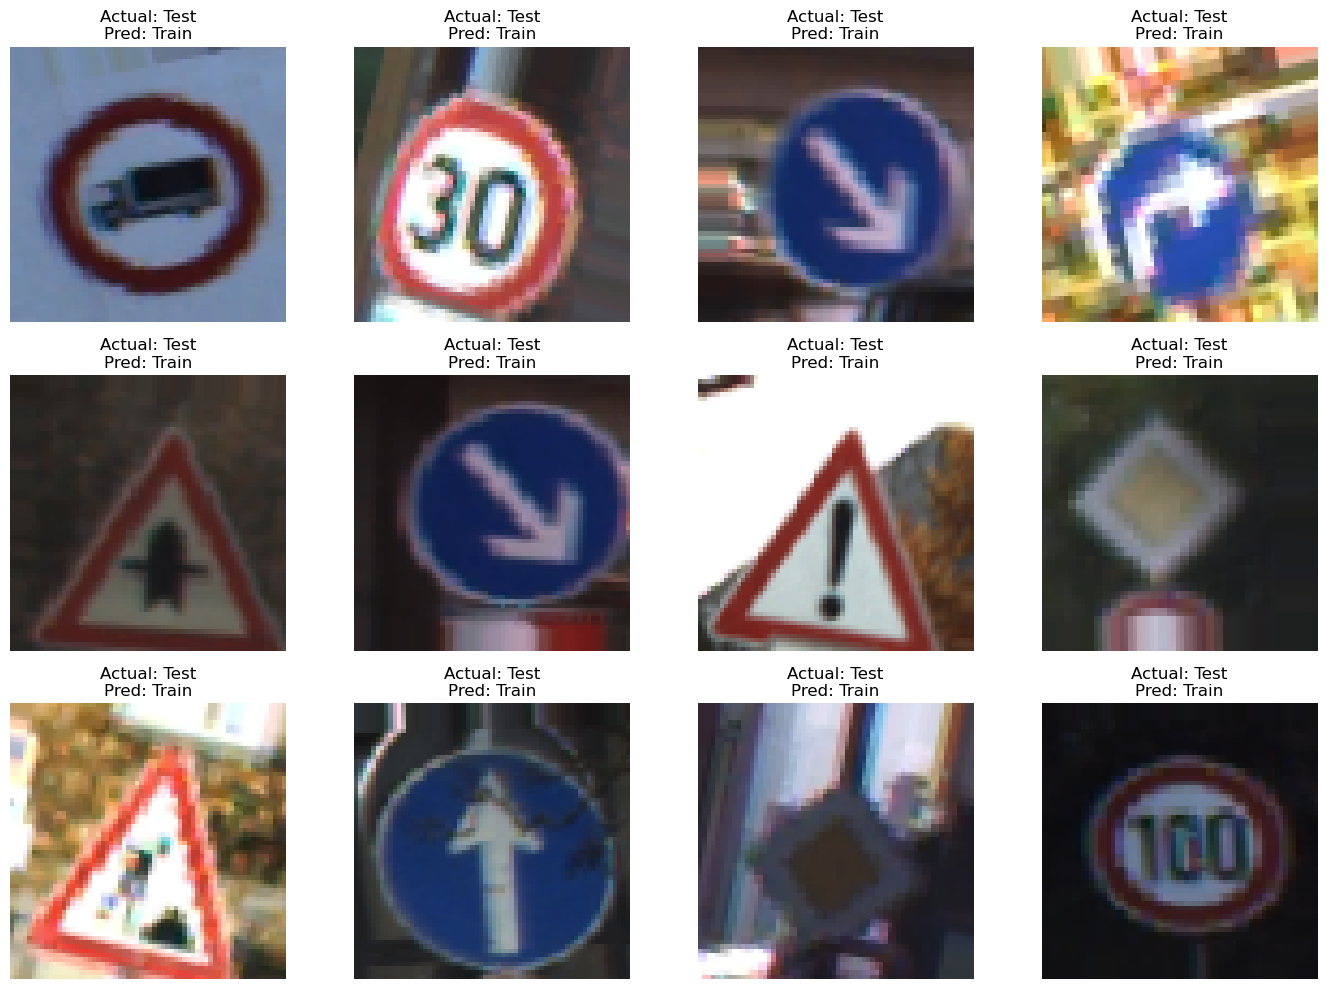

In [122]:
wrong_indices = np.where(
    misclassified
)[0]

plt.figure(figsize=(14, 10))

for i, idx in enumerate(
    wrong_indices[:12]
):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        all_images[idx]
    )

    actual = index_to_class[
        all_labels[idx]
    ]

    predicted = index_to_class[
        pred_classes[idx]
    ]

    plt.title(
        f"Actual: {actual}\nPred: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## Save trained model

In [123]:
model.save(
    "traffic_sign_classifier.keras"
)

print(
    "Model saved successfully"
)

Model saved successfully


## Load saved model

In [124]:
loaded_model = tf.keras.models.load_model(
    "traffic_sign_classifier.keras"
)

loaded_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,050,763 (7.82 MB)

 Trainable params: 683,587 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,367,176 (5.22 MB)

## Create prediction function

In [136]:
def predict_traffic_sign(
    image_path,
    model,
    index_to_class,
    img_size=64
):

    img = Image.open(
        image_path
    ).convert("RGB")

    img = img.resize(
        (img_size, img_size)
    )

    img_array = np.array(
        img
    ) / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    probabilities = model.predict(
        img_array,
        verbose=0
    )[0]

    predicted_index = np.argmax(
        probabilities
    )

    predicted_class = index_to_class[
        predicted_index
    ]

    confidence = probabilities[
        predicted_index
    ]

    return (
        predicted_class,
        confidence
    )

## Test with a new image

In [126]:
test_image_path = r"C:\Users\venka\Downloads\PRAICP-1002-TrafSignDetc\Test\12438.png"

predicted_class, confidence = (
    predict_traffic_sign(
        test_image_path,
        loaded_model,
        index_to_class,
        IMG_SIZE
    ) 
)

print(
    "Predicted Traffic Sign:",
    predicted_class
)

print(
    "Confidence:",
    round(confidence * 100, 2),
    "%"
)

predicted_class, confidence = (
    predict_traffic_sign(
        test_image_path,
        loaded_model,
        index_to_class,
        IMG_SIZE
    )
)

print(
    "Predicted Traffic Sign:",
    predicted_class
)

print(
    "Confidence:",
    round(confidence * 100, 2),
    "%"
)

Predicted Traffic Sign: Train
Confidence: 75.67 %
Predicted Traffic Sign: Train
Confidence: 75.67 %


## Display prediction

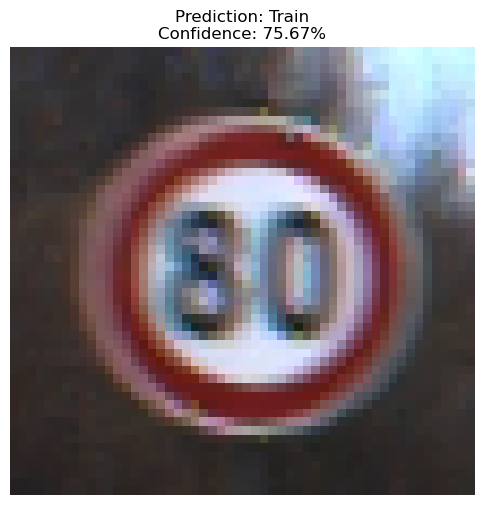

In [127]:
img = Image.open(
    test_image_path
).convert("RGB")

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)

plt.axis("off")

plt.show()

## Top-5 predictions

In [128]:
img = Image.open(
    test_image_path
).convert("RGB")

img = img.resize(
    (IMG_SIZE, IMG_SIZE)
)

img_array = np.array(img) / 255.0

img_array = np.expand_dims(
    img_array,
    axis=0
)

probabilities = loaded_model.predict(
    img_array,
    verbose=0
)[0]

top_indices = np.argsort(
    probabilities
)[-5:][::-1]

top_predictions = pd.DataFrame({
    "Class": [
        index_to_class[i]
        for i in top_indices
    ],

    "Probability": [
        probabilities[i]
        for i in top_indices
    ]
})

top_predictions

,Class,Probability
0,Train,0.756704
1,Test,0.243281
2,Meta,0.000015


In [ ]:
## Top-5 prediction chart

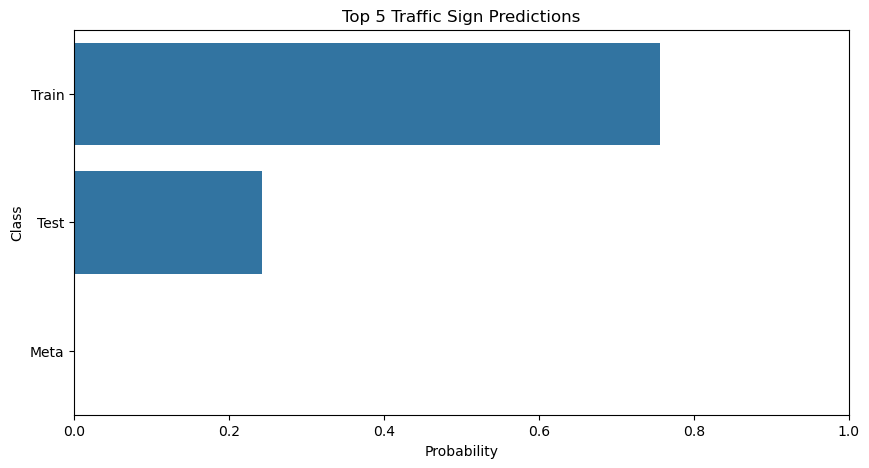

In [129]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_predictions,
    x="Probability",
    y="Class"
)

plt.title(
    "Top 5 Traffic Sign Predictions"
)

plt.xlim(0, 1)

plt.show()

In [ ]:
## Model architecture summary

In [130]:

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,050,763 (7.82 MB)

 Trainable params: 683,587 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,367,176 (5.22 MB)

In [ ]:
## Calculate total parameters

In [131]:
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Non-trainable parameters:",
    non_trainable_params
)

Trainable parameters: 683587
Non-trainable parameters: 0.0


In [ ]:
## Save class mapping

In [132]:
import json

with open(
    "traffic_sign_class_mapping.json",
    "w"
) as f:

    json.dump(
        index_to_class,
        f,
        indent=4
    )

print(
    "Class mapping saved"
)

Class mapping saved


In [ ]:
## Final model evaluation table

In [133]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Validation Loss"
    ],

    "Value": [
        validation_accuracy,
        validation_loss
    ]
})

final_metrics

,Metric,Value
0,Validation Accuracy,0.756530
1,Validation Loss,0.554636


## Final project conclusion

In [134]:
print("""
PROJECT CONCLUSION
==================

1. The traffic-sign image dataset was loaded and explored.

2. Images were checked for dimensions, class distribution,
   and corrupted files.

3. Images were resized to a common dimension and normalized
   to the range 0-1.

4. Data augmentation was applied to improve model
   generalization.

5. A CNN model was developed for traffic-sign classification.

6. The model was evaluated using:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion Matrix

7. Misclassified images were analyzed to identify classes
   that are difficult for the model to distinguish.

8. The trained CNN model was saved and can be reused to
   classify new traffic-sign images.

9. The final model can be used as a component of an
   intelligent traffic-sign recognition system.
""")


PROJECT CONCLUSION

1. The traffic-sign image dataset was loaded and explored.

2. Images were checked for dimensions, class distribution,
   and corrupted files.

3. Images were resized to a common dimension and normalized
   to the range 0-1.

4. Data augmentation was applied to improve model
   generalization.

5. A CNN model was developed for traffic-sign classification.

6. The model was evaluated using:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion Matrix

7. Misclassified images were analyzed to identify classes
   that are difficult for the model to distinguish.

8. The trained CNN model was saved and can be reused to
   classify new traffic-sign images.

9. The final model can be used as a component of an
   intelligent traffic-sign recognition system.

